# Rate My Recipe

## 1. Project Overview

This project investigates how recipes should be ranked using user ratings.

A simple average rating may produce misleading rankings because it does not
account for the number of reviews. For example, a recipe with a 5.0 average
rating based on two reviews may rank above a recipe with a 4.9 average based
on thousands of reviews.

The objective of this project is to develop and evaluate a more robust recipe
ranking strategy using both rating quality and review volume.

## 2. Data Loading and Initial Inspection

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_processing import (
    load_data,
    clean_interactions,
    build_recipe_stats
)

from src.ranking import (
    add_weighted_score,
    rank_recipes
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

In [19]:
PROJECT_ROOT = Path.cwd()

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder:", RAW_DATA_DIR)

Project root: /Users/metinvs/Coding for Data Science and Data Management
Raw data folder: /Users/metinvs/Coding for Data Science and Data Management/data/raw


In [20]:
# Load raw Food.com datasets
recipes, interactions = load_data(RAW_DATA_DIR)

print("Recipes loaded")
print("Interactions loaded")

Recipes loaded
Interactions loaded


In [21]:
print("Recipes shape:", recipes.shape)
print("Interactions shape:", interactions.shape)

Recipes shape: (231637, 12)
Interactions shape: (1132367, 5)


In [22]:
recipes.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-ame...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourths', 'remove seeds', ...","autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or sweet, your choice!\r\nt...","['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-ame...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of a 12 inch pizza pan', 'bake for 5 minute...",this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to change sausage to ham o...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietary', 'equipment', '4-...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when almost brown and sautee until wilted', 'a...",this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra large pot to have som...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoes', 'kidney beans', ...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', 'side-dishes', 'eggs-...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,"['place potatoes in a large pot of lightly salted water and bring to a gentle boil', 'cook until potatoes are just t...","this is a super easy, great tasting, make ahead side dish that looks like you spent a lot more time preparing than y...","['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', 'olive oil', 'red win...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion', 'north-american', '...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,"['mix all ingredients& boil for 2 1 / 2 hours , or until thick', 'pour into jars', ""i use'old' glass ketchup bottles...",my dh's amish mother raised him on this recipe. he much prefers it over store-bought ketchup. it was a taste i had t...,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', 'dry mustard']",8


In [23]:
interactions.head()

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for 15 minutes.Added a shake of cayenne and a pinch of salt. Used low fa...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall evening. Should have doubled it ;)<br/><br/>Second time around, forgo..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not quite a whole package (10oz) of white chips. Great!
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunko. Everyone loved it.
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprinkling of black pepper. Yum!"


In [24]:
recipes.info()

<class 'pandas.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   name            231636 non-null  str  
 1   id              231637 non-null  int64
 2   minutes         231637 non-null  int64
 3   contributor_id  231637 non-null  int64
 4   submitted       231637 non-null  str  
 5   tags            231637 non-null  str  
 6   nutrition       231637 non-null  str  
 7   n_steps         231637 non-null  int64
 8   steps           231637 non-null  str  
 9   description     226658 non-null  str  
 10  ingredients     231637 non-null  str  
 11  n_ingredients   231637 non-null  int64
dtypes: int64(5), str(7)
memory usage: 21.2 MB


In [25]:
interactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1132367 entries, 0 to 1132366
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1132367 non-null  int64
 1   recipe_id  1132367 non-null  int64
 2   date       1132367 non-null  str  
 3   rating     1132367 non-null  int64
 4   review     1132198 non-null  str  
dtypes: int64(3), str(2)
memory usage: 43.2 MB


In [26]:
interactions["rating"].value_counts().sort_index()

rating
0     60847
1     12818
2     14123
3     40855
4    187360
5    816364
Name: count, dtype: int64

In [27]:
def missing_summary(df):
    summary = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100
    })

    return summary.sort_values(
        "missing_percent",
        ascending=False
    )

missing_summary(recipes)
## More Readable

,missing_count,missing_percent
description,4979,2.149484
name,1,0.000432
id,0,0.000000
minutes,0,0.000000
contributor_id,0,0.000000
submitted,0,0.000000
tags,0,0.000000
nutrition,0,0.000000
n_steps,0,0.000000
steps,0,0.000000


In [28]:
missing_summary(interactions)

,missing_count,missing_percent
review,169,0.014924
user_id,0,0.000000
recipe_id,0,0.000000
date,0,0.000000
rating,0,0.000000


In [29]:
# Clean interaction data by treating rating 0 as a missing star rating
interactions_clean = clean_interactions(interactions)

print("Missing ratings:", interactions_clean["rating"].isna().sum())
print("Valid ratings:", interactions_clean["rating"].notna().sum())

Missing ratings: 60847
Valid ratings: 1071520


In [30]:
# Check the rating distribution after removing non-ratings
interactions_clean["rating"].value_counts().sort_index()

rating
1.0     12818
2.0     14123
3.0     40855
4.0    187360
5.0    816364
Name: count, dtype: int64

In [32]:
# Build one recipe-level dataset with average rating and rating count
recipe_stats = build_recipe_stats(
    recipes,
    interactions_clean
)

print("Final recipe-level dataset:", recipe_stats.shape)

recipe_stats[
    [
        "name",
        "minutes",
        "n_steps",
        "n_ingredients",
        "avg_rating",
        "n_ratings"
    ]
].head()

Final recipe-level dataset: (231637, 14)


,name,minutes,n_steps,n_ingredients,avg_rating,n_ratings
0,arriba baked winter squash mexican style,55,11,7,5.000000,3
1,a bit different breakfast pizza,30,9,6,4.666667,3
2,all in the kitchen chili,130,6,13,4.000000,1
3,alouette potatoes,45,11,11,4.500000,2
4,amish tomato ketchup for canning,190,5,8,5.000000,1


In [33]:
# Inspect review-count distribution among recipes with valid ratings
valid_rating_counts = recipe_stats.loc[
    recipe_stats["n_ratings"] > 0,
    "n_ratings"
]

valid_rating_counts.quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

0.25     1.0
0.50     2.0
0.75     4.0
0.90     9.0
0.95    14.0
0.99    45.0
Name: n_ratings, dtype: float64

In [34]:
# Count recipes with no valid star rating
no_rating_count = (recipe_stats["n_ratings"] == 0).sum()

print("Recipes with no valid ratings:", no_rating_count)
print(
    "Percentage:",
    round(no_rating_count / len(recipe_stats) * 100, 2),
    "%"
)

Recipes with no valid ratings: 5047
Percentage: 2.18 %


### Naive ranking

The simplest approach is to rank recipes by their average rating.

However, this method ignores the number of ratings. A recipe with only one
5-star rating can therefore appear above a recipe with thousands of highly
positive ratings.

For this reason, average rating alone may not provide a reliable ranking.

In [35]:
# Naive ranking: recipes are ranked only by their average rating
naive_ranking = (
    recipe_stats[
        recipe_stats["n_ratings"] > 0
    ]
    .sort_values(
        "avg_rating",
        ascending=False
    )
)

naive_ranking[
    ["name", "avg_rating", "n_ratings"]
].head(10)

,name,avg_rating,n_ratings
0,arriba baked winter squash mexican style,5.0,3
104895,herb you roasted my turkey,5.0,1
104920,herb crusted pork loin,5.0,1
104919,herb crusted halibut,5.0,1
104918,herb crusted fish,5.0,2
104916,herb crumbled broccoli,5.0,1
104914,herb cooked halibut,5.0,1
198690,squash brownies,5.0,6
104907,herb balsamic sauce,5.0,4
104906,herb baked scallops,5.0,1


In [36]:
# Global average rating across all valid user ratings
C = interactions_clean["rating"].mean()

print("Global average rating:", round(C, 3))

Global average rating: 4.661


### Weighted ranking

To reduce the impact of recipes with very few ratings, a weighted rating score
is introduced.

The score combines each recipe's average rating with the overall average rating
of the platform. Recipes with many ratings receive more weight on their own
average, while recipes with only a few ratings are pulled toward the global
mean.

This produces a more reliable ranking than using the raw average alone.

In [38]:
# Define valid-rating recipes and test alternative confidence thresholds
mask = recipe_stats["n_ratings"] > 0

positive_ratings = recipe_stats.loc[
    mask,
    "n_ratings"
]

rating_quantiles = positive_ratings.quantile(
    [0.90, 0.95, 0.99]
)

rating_quantiles

0.90     9.0
0.95    14.0
0.99    45.0
Name: n_ratings, dtype: float64

In [39]:
# Calculate weighted scores for alternative confidence thresholds
for q, threshold in rating_quantiles.items():

    column_name = f"weighted_{int(q * 100)}"

    recipe_stats = add_weighted_score(
        recipe_stats,
        global_mean=C,
        min_ratings=threshold,
        column_name=column_name
    )

print("Sensitivity scores created")

Sensitivity scores created


### Sensitivity analysis

The confidence threshold determines how strongly recipes with few ratings
are penalized.

To avoid choosing this parameter arbitrarily, I compared thresholds based
on the 90th, 95th and 99th percentiles of the review-count distribution.

In [40]:
# Measure how similar the top rankings are under different thresholds
top_n = 20

top90 = set(
    recipe_stats.nlargest(top_n, "weighted_90")["id"]
)

top95 = set(
    recipe_stats.nlargest(top_n, "weighted_95")["id"]
)

top99 = set(
    recipe_stats.nlargest(top_n, "weighted_99")["id"]
)

print(
    "90 vs 95 overlap:",
    len(top90 & top95),
    "/",
    top_n
)

print(
    "90 vs 99 overlap:",
    len(top90 & top99),
    "/",
    top_n
)

print(
    "95 vs 99 overlap:",
    len(top95 & top99),
    "/",
    top_n
)

90 vs 95 overlap: 16 / 20
90 vs 99 overlap: 7 / 20
95 vs 99 overlap: 11 / 20


### Final threshold selection

The 90th, 95th and 99th percentiles correspond to confidence thresholds
of 9, 14 and 45 ratings.

The top-20 rankings obtained with the 90th and 95th percentiles shared
16 recipes, while the 99th-percentile ranking differed substantially more.

Therefore, the 95th percentile (m = 14) was selected as a balanced
confidence threshold: it reduces the influence of very small samples
without placing excessive weight on only the most-reviewed recipes.

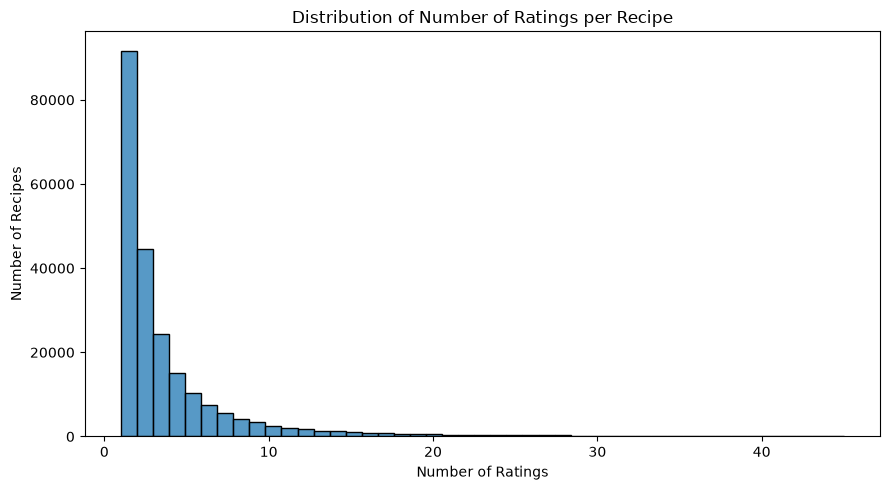

In [41]:
# Visualize how unevenly reviews are distributed across recipes
review_limit = rating_quantiles.loc[0.99]

plt.figure(figsize=(9, 5))

sns.histplot(
    recipe_stats.loc[
        recipe_stats["n_ratings"].between(1, review_limit),
        "n_ratings"
    ],
    bins=int(review_limit)
)

plt.title("Distribution of Number of Ratings per Recipe")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

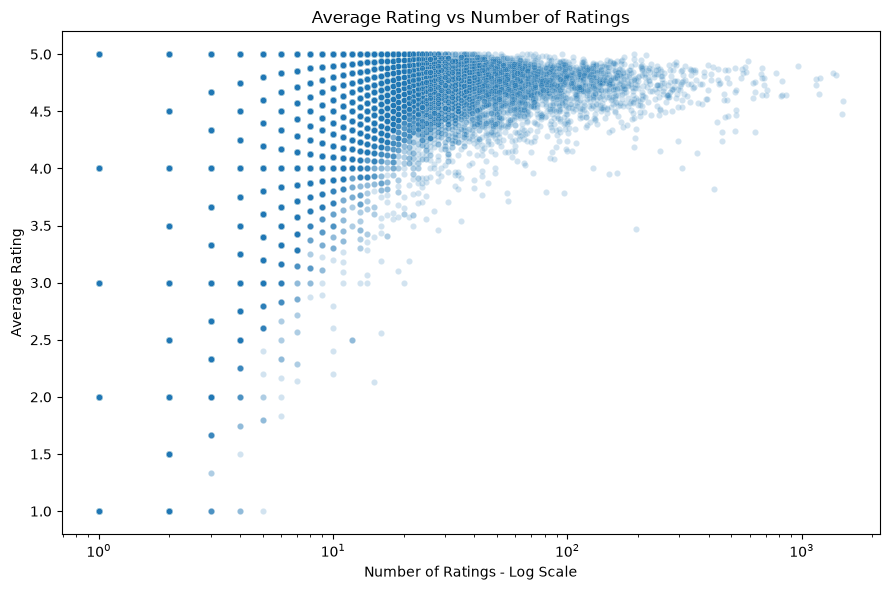

In [42]:
# Explore whether high average ratings are supported by many reviews
plot_data = recipe_stats[
    (recipe_stats["n_ratings"] > 0)
    & (recipe_stats["avg_rating"].notna())
].copy()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_data,
    x="n_ratings",
    y="avg_rating",
    alpha=0.20,
    s=20
)

plt.xscale("log")

plt.title("Average Rating vs Number of Ratings")
plt.xlabel("Number of Ratings - Log Scale")
plt.ylabel("Average Rating")

plt.tight_layout()
plt.show()

In [43]:
# Final model: use the 95th percentile confidence threshold
FINAL_M = positive_ratings.quantile(0.95)

recipe_stats = add_weighted_score(
    recipe_stats,
    global_mean=C,
    min_ratings=FINAL_M,
    column_name="final_score"
)

final_ranking = rank_recipes(
    recipe_stats,
    "final_score"
)

print("Global mean C:", round(C, 3))
print("Final confidence threshold m:", FINAL_M)

final_ranking[
    ["name", "avg_rating", "n_ratings", "final_score"]
].head(10)

Global mean C: 4.661
Final confidence threshold m: 14.0


,name,avg_rating,n_ratings,final_score
12559,bacon lattice tomato muffins rsc,5.000000,192,4.976995
134684,mexican stack up rsc,4.990783,217,4.970827
57050,company s coming mashed potatoes,5.000000,95,4.956523
219839,uncle bill s method for cooking turkey,4.971429,175,4.948471
187582,simply irresistible tropical potato salad sp5,5.000000,73,4.945529
117961,kittencal s balsamic vinaigrette,5.000000,69,4.942903
211431,the best creole cajun seasoning mix,5.000000,67,4.941494
1082,2 handed kitchen sink tomato sandwich,4.987654,81,4.939589
157800,peppered buffalo ranch shrimp pizza rsc,5.000000,64,4.939243
45304,chicken pot pie with 2 crusts,4.958549,193,4.938459


In [45]:
# Compare typical recipes with the top 100 ranked recipes
top100 = final_ranking.head(100)

comparison = pd.DataFrame({
    "All Recipes": [
        recipe_stats["minutes"].median(),
        recipe_stats["n_ingredients"].median(),
        recipe_stats["n_steps"].median()
    ],
    "Top 100 Recipes": [
        top100["minutes"].median(),
        top100["n_ingredients"].median(),
        top100["n_steps"].median()
    ]
}, index=[
    "Median Preparation Time",
    "Median Ingredients",
    "Median Steps"
])

comparison

,All Recipes,Top 100 Recipes
Median Preparation Time,40.0,40.0
Median Ingredients,9.0,7.0
Median Steps,9.0,10.0


## Recipe Characteristics

To explore whether highly ranked recipes share common characteristics,
the top 100 recipes were compared with the full recipe dataset.

The median preparation time is identical at 40 minutes. Top-ranked recipes
use slightly fewer ingredients (7 compared with 9), while their median
number of preparation steps is slightly higher (10 compared with 9).

Overall, the results do not suggest a large difference in recipe complexity
between highly ranked recipes and the rest of the dataset.

## Conclusion

Average rating alone is not a reliable way to rank recipes because many
recipes receive only a small number of ratings.

The analysis therefore introduced a weighted rating that combines a recipe's
average rating with the overall platform average and the number of ratings
received.

A sensitivity analysis was used to compare several confidence thresholds,
and the 95th percentile (14 ratings) was selected for the final ranking.

The weighted approach reduces the influence of recipes with very few ratings
and produces a ranking supported by substantially more user feedback.

Finally, highly ranked recipes were found to have broadly similar preparation
times and complexity to the overall recipe population, although they tend to
use slightly fewer ingredients.

In [ ]:
## Performance Benchmark and Validation

The original row-wise Pandas implementation is compared with the
vectorized NumPy implementation in terms of execution time and
numerical equivalence.

Controlled test cases are also used to verify the correctness of
the weighted rating formula, including recipes without valid ratings.

In [47]:
import time
import importlib
import numpy as np
import src.ranking as ranking

importlib.reload(ranking)

# Select recipes with valid ratings
valid_recipes = recipe_stats.loc[
    recipe_stats["n_ratings"] > 0
].copy()

# Old method: row-wise apply
start = time.perf_counter()

old_scores = valid_recipes.apply(
    ranking.weighted_rating,
    axis=1,
    global_mean=C,
    min_ratings=14
)

old_time = time.perf_counter() - start

# New method: NumPy vectorization
start = time.perf_counter()

new_result = ranking.add_weighted_score(
    valid_recipes,
    global_mean=C,
    min_ratings=14
)

new_time = time.perf_counter() - start

# Validate numerical results
same_results = np.allclose(
    old_scores.to_numpy(),
    new_result["weighted_score"].to_numpy()
)

assert same_results, "Weighted scores do not match!"

# Display results
print(f"Recipes tested: {len(valid_recipes):,}")
print(f"Old method: {old_time:.4f} seconds")
print(f"New method: {new_time:.4f} seconds")
print(f"Speed improvement: {old_time / new_time:.2f}x")
print(f"Same results: {same_results}")

Recipes tested: 226,590
Old method: 0.7797 seconds
New method: 0.0192 seconds
Speed improvement: 40.52x
Same results: True


In [48]:
# Validate weighted ranking using controlled test data

test_data = pd.DataFrame({
    "avg_rating": [5.0, 4.0, 4.8, np.nan],
    "n_ratings": [14, 14, 1000, 0]
})

test_result = ranking.add_weighted_score(
    test_data,
    global_mean=4.5,
    min_ratings=14
)

assert np.isclose(test_result.loc[0, "weighted_score"], 4.75)
assert np.isclose(test_result.loc[1, "weighted_score"], 4.25)
assert np.isclose(test_result.loc[2, "weighted_score"], 4.7958579882)
assert pd.isna(test_result.loc[3, "weighted_score"])

print("All validation tests passed!")

test_result

All validation tests passed!


,avg_rating,n_ratings,weighted_score
0,5.0,14,4.750000
1,4.0,14,4.250000
2,4.8,1000,4.795858
3,NaN,0,NaN
